# Floating-streamer VES / continuous resistivity profiling

An illustrative **11-electrode, 5 m spacing dipoleâ€“dipole streamer**:
A=0 m, B=5 m; potential pairs M=10...45 m, N=M+5 m (8 channels).
One local 1D water-plus-sediment model is fitted per acquisition station.
This is not a 2D ERT inversion: bathymetric relief, shorelines, streamer
curvature and lateral changes across the 50 m array can invalidate 1D fits.

[EPA continuous resistivity profiling](https://www.epa.gov/environmental-geophysics/continuous-resistivity-profiling)

The known water layer is fixed. Synthetic data are clearly labelled; replace
them with measured CSV data and water properties before interpretation.
No conversion of dipoleâ€“dipole geometry into Schlumberger AB/2 is made.

In [7]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import j0
from scipy.special import roots_legendre

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pytem').is_dir())
sys.path.insert(0, str(ROOT))

from ves.ves import _dc_recursion, _analytic_jac_at_lambda
from pytem import invert_joint
from pytem.plotter import plot_model, plot_survey_models

## 1. Array and geometry-correct 1D response

For surface electrodes, V/I = [P(AM)-P(BM)-P(AN)+P(BN)]/(2 pi),
where P(r) is the layered-earth surface potential kernel. The signed
geometric factor is computed from the same distances. Keep electrode and
voltage polarity conventions consistent.

Reuse the VES layer recursion and analytical sensitivities. Cache quadrature,
Bessel functions and the last forward/Jacobian pair. Integrate only the
departure from the homogeneous water half-space; its 1/r term is exact.
The cutoff uses the fixed water thickness, so submerged electrodes require
a different forward model. A 1024/2048-point comparison below checks accuracy.

In [8]:
spacing = 5.0
A = np.zeros(8)
B = np.full(8, spacing)
M = spacing * np.arange(2, 10)
N = M + spacing

def streamer_system(A, B, M, N, water_depth, water_rho,
                    sediment_thicknesses, order=1024):
    electrodes = np.asarray([A, B, M, N], dtype=float)
    thicknesses = np.asarray(sediment_thicknesses, dtype=float)
    if (electrodes.ndim != 2 or electrodes.shape[0] != 4
            or electrodes.shape[1] == 0 or not np.isfinite(electrodes).all()):
        raise ValueError('Provide four finite, matching electrode coordinate arrays.')
    if (not np.isfinite(water_depth) or water_depth <= 0
            or not np.isfinite(water_rho) or water_rho <= 0
            or thicknesses.ndim != 1 or not np.isfinite(thicknesses).all()
            or np.any(thicknesses <= 0)):
        raise ValueError('Require positive water properties and sediment thicknesses.')
    a, b, m, n = electrodes
    distances = np.abs(np.array([a-m, b-m, a-n, b-n]))
    if np.any(distances == 0):
        raise ValueError('Current and potential electrodes must not coincide.')
    signs = np.array([1., -1., -1., 1.])
    denominator = signs @ (1 / distances)
    if np.any(np.abs(denominator) < 1e-12):
        raise ValueError('Degenerate electrode geometry.')
    geometric_factor = 2 * np.pi / denominator

    nodes, weights = roots_legendre(order)
    cutoff = 18 / water_depth
    lambdas = (nodes + 1) * cutoff / 2
    weights = weights * cutoff / 2
    bessel = j0(distances[:, :, None] * lambdas)
    integration = np.einsum('i,ijk,k->jk', signs, bessel, weights)
    integration /= denominator[:, None]
    full_thicknesses = np.r_[water_depth, thicknesses]
    cached_model = cached_response = cached_jacobian = None

    def evaluate(log_rho):
        nonlocal cached_model, cached_response, cached_jacobian
        log_rho = np.asarray(log_rho, dtype=float)
        if (log_rho.shape != (thicknesses.size + 1,)
                or not np.isfinite(log_rho).all()):
            raise ValueError('Require one finite log-resistivity per sediment layer.')
        if cached_model is None or not np.array_equal(log_rho, cached_model):
            rho = np.r_[water_rho, np.exp(log_rho)]
            kernel = np.empty(order)
            gradient = np.empty((order, log_rho.size))
            for i, lam in enumerate(lambdas):
                kernel[i], values, tau, sech2, denom = _dc_recursion(
                    lam, rho, full_thicknesses)
                drho, _ = _analytic_jac_at_lambda(
                    lam, rho, values, tau, sech2, denom)
                gradient[i] = drho[1:] * rho[1:]
            cached_response = water_rho + integration @ (kernel - water_rho)
            cached_jacobian = integration @ gradient
            cached_model = log_rho.copy()
        return cached_response, cached_jacobian

    return {
        'forward': lambda m: evaluate(m)[0].copy(),
        'jacobian': lambda m: evaluate(m)[1].copy(),
        'geometric_factor': geometric_factor,
    }

## 2. Data: synthetic example or measured CSV

CSV columns (one row per channel and acquisition station):

`station, distance_m, water_depth_m, water_rho_ohmm, A_m, B_m, M_m, N_m, rhoa_ohmm, error_fraction`

Electrode coordinates are along a straight floating array, in metres.
Apparent resistivity must use the signed geometric factor and matching V/I
polarity. Water resistivity is **ohm m**, not conductivity; rho=1/sigma
for conductivity in S/m. All channels at a station share its water properties.
`distance_m` is the acquisition reference position, not each channel midpoint.

Illustrative values: 2 m water depth and 5 ohm m water resistivity.
These are not measurements or site assumptions.

In [9]:
CSV_PATH = None  # e.g. Path('data/streamer_measurements.csv')
# Smooth inversion: 30 sediment layers, fixed boundaries to 30 m.
sediment_tops = np.r_[0., np.geomspace(0.3, 30., 29)]
sediment_thicknesses = np.diff(sediment_tops)
truth_thicknesses = np.array([3., 7., 15.])
rho_start = np.full(sediment_thicknesses.size + 1, 20.)
synthetic_truth = {}

if CSV_PATH is None:
    rng = np.random.default_rng(42)
    rows = []
    for station, distance in enumerate([0., 25., 50.]):
        truth = np.array([12., 35. + station * 10., 8., 60.])
        synthetic_truth[station] = truth
        system = streamer_system(A, B, M, N, 2., 5., truth_thicknesses)
        clean = system['forward'](np.log(truth))
        measured = clean * np.exp(rng.normal(0, 0.03, clean.size))
        for channel in range(clean.size):
            rows.append(dict(
                station=station, distance_m=distance, water_depth_m=2.,
                water_rho_ohmm=5., A_m=A[channel], B_m=B[channel],
                M_m=M[channel], N_m=N[channel],
                rhoa_ohmm=measured[channel], error_fraction=0.03))
    data = pd.DataFrame(rows)
    print('SYNTHETIC DATA: 3 stations, 8 channels each.')
else:
    data = pd.read_csv(CSV_PATH)

required = ['station', 'distance_m', 'water_depth_m', 'water_rho_ohmm',
            'A_m', 'B_m', 'M_m', 'N_m', 'rhoa_ohmm', 'error_fraction']
missing = set(required) - set(data.columns)
if missing:
    raise ValueError(f'Missing CSV columns: {sorted(missing)}')
if data.empty or data['station'].isna().any():
    raise ValueError('Require nonempty data and station identifiers.')
if not np.isfinite(data[required[1:]].to_numpy(dtype=float)).all():
    raise ValueError('All numeric CSV values must be finite.')
if (data[['water_depth_m', 'water_rho_ohmm', 'rhoa_ohmm',
          'error_fraction']] <= 0).any().any():
    raise ValueError('Water properties, apparent resistivity and errors must be positive.')
data.head()

SYNTHETIC DATA: 3 stations, 8 channels each.


,station,distance_m,water_depth_m,water_rho_ohmm,A_m,B_m,M_m,N_m,rhoa_ohmm,error_fraction
0,0,0.0,2.0,5.0,0.0,5.0,10.0,15.0,7.664995,0.03
1,0,0.0,2.0,5.0,0.0,5.0,15.0,20.0,10.248188,0.03
2,0,0.0,2.0,5.0,0.0,5.0,20.0,25.0,13.248949,0.03
3,0,0.0,2.0,5.0,0.0,5.0,25.0,30.0,15.000714,0.03
4,0,0.0,2.0,5.0,0.0,5.0,30.0,35.0,14.651880,0.03


## 3. Numerical checks

Check a homogeneous half-space, quadrature refinement and analytical
sensitivities against centred finite differences before inversion.

In [10]:
sample = data[data['station'] == data['station'].iloc[0]]
args = [sample[c].to_numpy() for c in ['A_m', 'B_m', 'M_m', 'N_m']]
water_depth = float(sample['water_depth_m'].iloc[0])
water_rho = float(sample['water_rho_ohmm'].iloc[0])
base = streamer_system(*args, water_depth, water_rho, sediment_thicknesses)
fine = streamer_system(*args, water_depth, water_rho, sediment_thicknesses, order=2048)
np.testing.assert_allclose(
    base['forward'](np.full(rho_start.size, np.log(water_rho))),
    water_rho, rtol=1e-10, atol=1e-10)
test_model = np.log(np.geomspace(12., 60., rho_start.size))
np.testing.assert_allclose(base['forward'](test_model), fine['forward'](test_model),
                           rtol=1e-5, atol=1e-5)
analytic = base['jacobian'](test_model)
fd = np.empty_like(analytic)
for layer in range(test_model.size):
    delta = np.zeros(test_model.size)
    delta[layer] = 1e-4
    fd[:, layer] = (base['forward'](test_model + delta)
                    - base['forward'](test_model - delta)) / 2e-4
np.testing.assert_allclose(analytic, fd, rtol=1e-4, atol=1e-5)
print('PASS: homogeneous response, quadrature refinement and analytical Jacobian.')

PASS: homogeneous response, quadrature refinement and analytical Jacobian.


## 4. Independent local 1D inversions

Reuse `pytem.invert_joint` directly with geometry-correct forward/Jacobian
callbacks. Only sediment resistivities vary; water properties and layer
thicknesses stay fixed. Automatic regularization targets noise-weighted RMS
near 1. A good fit does not establish uniqueness or validate the 1D assumption.

Smooth inversion uses 30 fixed sediment layers with first-difference L2 roughness on log-resistivity. `adaptive_alpha=True` fits alpha near the noise target RMS=1 rather than accepting a large undershoot. Only eight channels constrain this fine grid: deeper structure remains regularization-dependent, not independently resolved.


In [11]:
results = {}
stations = []
for station, group in data.groupby('station', sort=False):
    for column in ['distance_m', 'water_depth_m', 'water_rho_ohmm']:
        if group[column].nunique() != 1:
            raise ValueError(f'{column} must be constant within station {station}.')
    system = streamer_system(
        *[group[c].to_numpy() for c in ['A_m', 'B_m', 'M_m', 'N_m']],
        float(group['water_depth_m'].iloc[0]),
        float(group['water_rho_ohmm'].iloc[0]), sediment_thicknesses)
    obs = group['rhoa_ohmm'].to_numpy()
    system.update(obs=obs, noise=obs * group['error_fraction'].to_numpy())
    result = invert_joint(
        [system], thicknesses=sediment_thicknesses, rho_start=rho_start,
        rho_min=0.1, rho_max=1e4, maxit=30, alpha_steps=10,
        alpha_step=1/3, norm='l2', adaptive_alpha=True, verbose=False)
    np.testing.assert_allclose(
        system['forward'](result['log_resistivities']),
        streamer_system(
            *[group[c].to_numpy() for c in ['A_m', 'B_m', 'M_m', 'N_m']],
            float(group['water_depth_m'].iloc[0]),
            float(group['water_rho_ohmm'].iloc[0]), sediment_thicknesses,
            order=2048)['forward'](result['log_resistivities']),
        rtol=1e-5, atol=1e-5)
    results[station] = result
    stations.append(station)
    print(station, 'RMS:', round(result['rms'], 3),
          'alpha:', result['alpha_final'],
          'converged:', result['converged'], result['termination_reason'])

0 RMS: 0.997 alpha: 4.639501291724731 converged: True converged
1 RMS: 0.987 alpha: 16.65482414940321 converged: True converged
2 RMS: 0.998 alpha: 13.573758945660703 converged: True converged


## 5. Models and data fits

Sediment model depths are measured **below the water bottom**. Water is not
included in the plotted sediment profiles. Acquisition stations remain local
1D fits, not a continuous 2D section or a depth-of-investigation estimate.

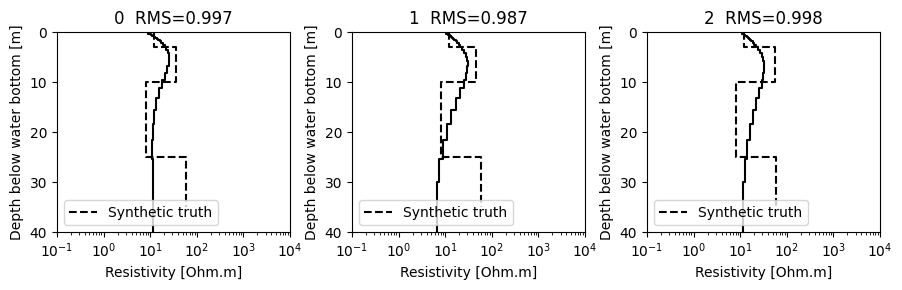

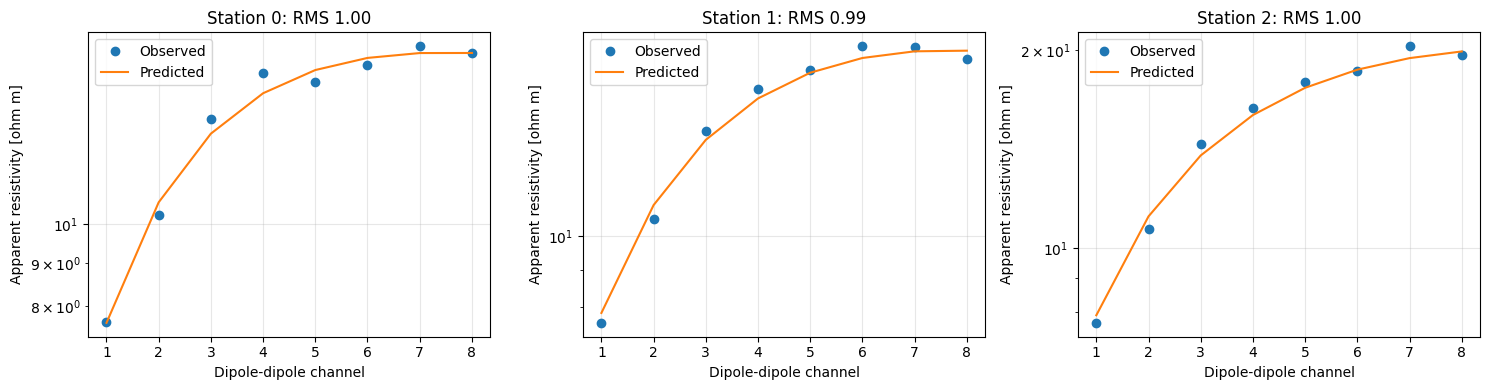

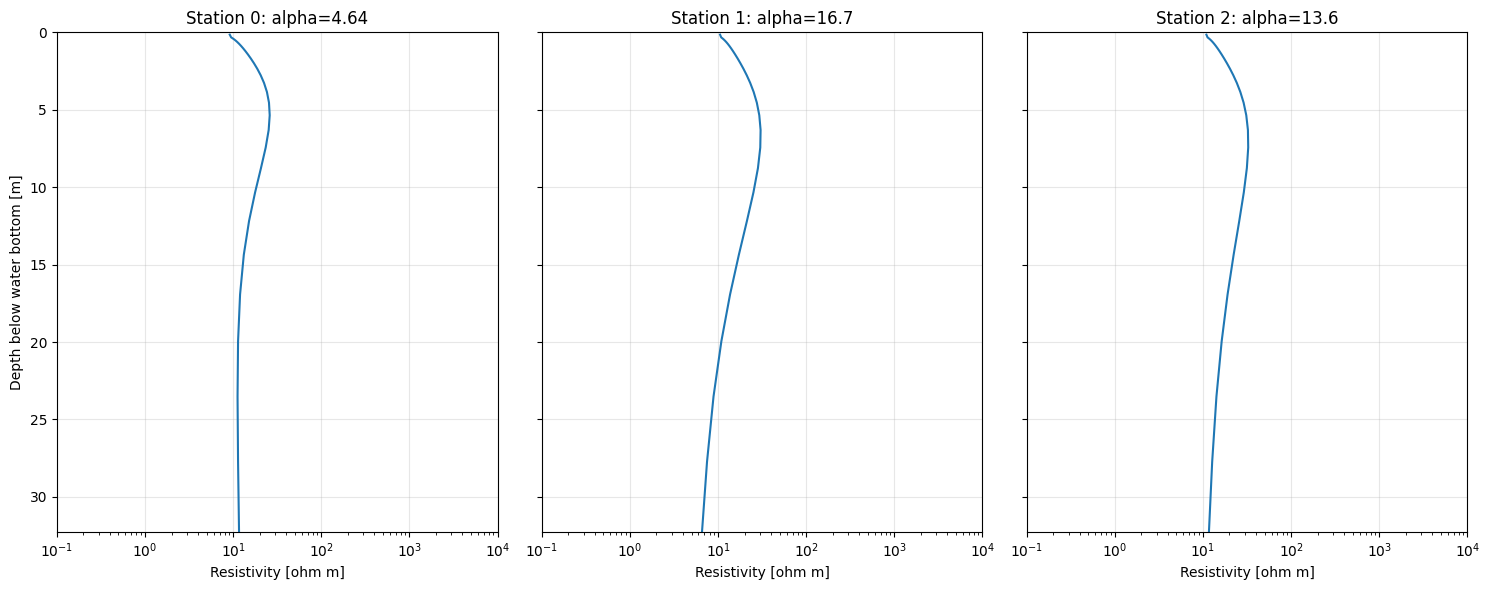

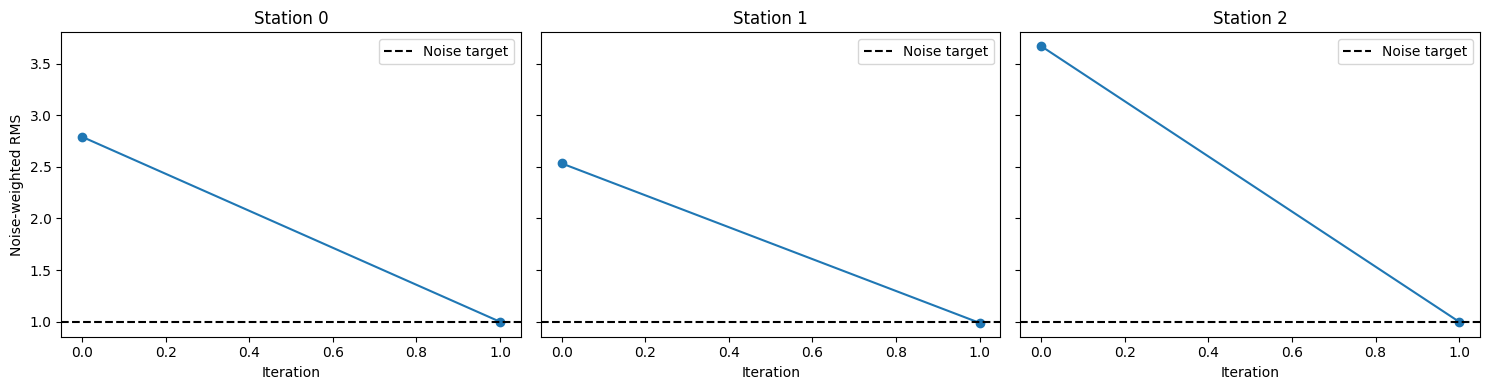

In [12]:
models = np.array([results[s]['resistivities'] for s in stations])
rms = np.array([results[s]['rms'] for s in stations])
fig, axes = plot_survey_models(
    sediment_thicknesses, models, rms=rms,
    station_names=[str(s) for s in stations], n_cols=len(stations),
    xlim=(0.1, 1e4), model_linestyle='-')
for ax, station in zip(axes, stations):
    ax.set_ylabel('Depth below water bottom [m]')
    if station in synthetic_truth:
        plot_model(truth_thicknesses, synthetic_truth[station], ax=ax,
                   label='Synthetic truth', color='k', linestyle='--',
                   title=ax.get_title(), xlim=(0.1, 1e4))
        ax.set_ylim(bottom=sum(sediment_thicknesses) + 10, top=0)
        ax.set_ylabel('Depth below water bottom [m]')
plt.show()

fig, axes = plt.subplots(1, len(stations), figsize=(5 * len(stations), 4),
                         squeeze=False)
for ax, station in zip(axes.ravel(), stations):
    result = results[station]
    channel = np.arange(1, result['observed'].size + 1)
    ax.semilogy(channel, result['observed'], 'o', label='Observed')
    ax.semilogy(channel, result['predicted'], '-', label='Predicted')
    ax.set(xlabel='Dipole-dipole channel', ylabel='Apparent resistivity [ohm m]',
           title=f'Station {station}: RMS {result["rms"]:.2f}')
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# Plot the fitted fine-layer model as connected layer-centre values.
# This displays the regularized inversion, not a smoothed four-layer truth.
finite_centres = sediment_tops[:-1] + sediment_thicknesses / 2
centres = np.r_[finite_centres, sediment_tops[-1] + sediment_thicknesses[-1] / 2]
fig, axes = plt.subplots(1, len(stations), figsize=(5 * len(stations), 6),
                         sharex=True, sharey=True, squeeze=False)
for ax, station in zip(axes.ravel(), stations):
    result = results[station]
    ax.semilogx(result['resistivities'], centres, '-', label='Smooth inversion')
    ax.set(xlabel='Resistivity [ohm m]', xlim=(0.1, 1e4),
           title=f'Station {station}: alpha={result["alpha_final"]:.3g}')
    ax.grid(alpha=0.3)
axes[0, 0].set_ylabel('Depth below water bottom [m]')
axes[0, 0].set_ylim(centres[-1], 0)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(stations), figsize=(5 * len(stations), 4),
                         sharex=True, sharey=True, squeeze=False)
for ax, station in zip(axes.ravel(), stations):
    ax.plot(results[station]['rms_history'], 'o-')
    ax.axhline(1., color='k', linestyle='--', label='Noise target')
    ax.set(xlabel='Iteration', title=f'Station {station}')
    ax.legend()
axes[0, 0].set_ylabel('Noise-weighted RMS')
fig.tight_layout()
plt.show()


## 6. Distance-depth resistivity section

Side-by-side independent 1D inversions, **not a 2D ERT inversion**. 
Depth is below the local water bottom; water is omitted. 
Station columns extend to midpoints between acquisition positions, 
without lateral smoothing. The half-space is drawn to a finite depth 
for display only; plotted depth does not imply resolved depth.


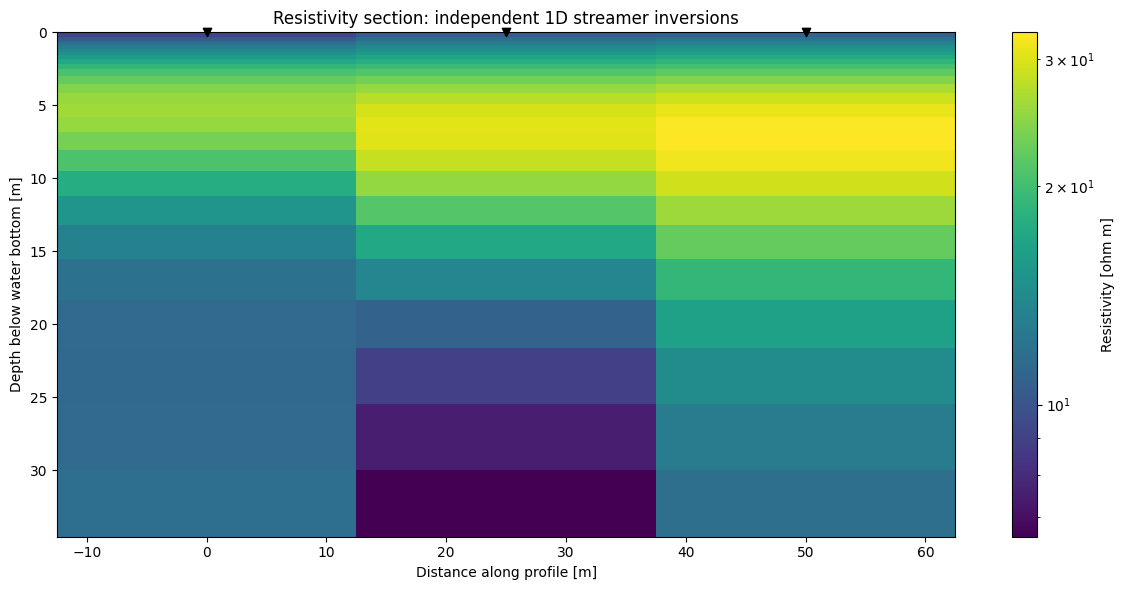

In [13]:
from matplotlib.colors import LogNorm

positions = np.array([
    data.loc[data['station'] == station, 'distance_m'].iloc[0]
    for station in stations
])
order = np.argsort(positions)
positions = positions[order]
if positions.size < 2 or np.any(np.diff(positions) <= 0):
    raise ValueError('The section requires at least two distinct station distances.')

x_edges = np.r_[
    positions[0] - (positions[1] - positions[0]) / 2,
    (positions[:-1] + positions[1:]) / 2,
    positions[-1] + (positions[-1] - positions[-2]) / 2,
]
depth_edges = np.r_[
    sediment_tops, sediment_tops[-1] + sediment_thicknesses[-1]
]
section_models = np.array([results[stations[i]]['resistivities'] for i in order])
vmin, vmax = section_models.min(), section_models.max()
if vmin == vmax:
    vmin, vmax = vmin / 1.1, vmax * 1.1

fig, ax = plt.subplots(figsize=(12, 6))
mesh = ax.pcolormesh(
    x_edges, depth_edges, section_models.T,
    norm=LogNorm(vmin=vmin, vmax=vmax), cmap='viridis', shading='flat',
)
ax.invert_yaxis()
ax.scatter(positions, np.zeros_like(positions), marker='v', c='k', clip_on=False)
ax.set(
    xlabel='Distance along profile [m]',
    ylabel='Depth below water bottom [m]',
    title='Resistivity section: independent 1D streamer inversions',
)
fig.colorbar(mesh, ax=ax, label='Resistivity [ohm m]')
fig.tight_layout()
plt.show()
